# Name That LLM — Exploration visuelle des données

Objectif : comprendre **ce qui distingue les 18 modèles** avant de modéliser.

Plan
1. Chargement & vue d'ensemble
2. Longueur des textes
3. Structure des prompts (1 prompt → ~18 réponses)
4. Empreintes stylistiques (ponctuation, markdown, structure)
5. Vocabulaire et débuts de texte distinctifs
6. Cartographie 2D : sujet vs style
7. Sujet ou style ? Mesure par similarité
8. Baseline rapide + matrice de confusion (où sont les confusions ?)
9. Train vs test
10. Conclusions

## 1. Chargement & vue d'ensemble

In [1]:
import pathlib, re, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

CANDIDATES = [
    pathlib.Path('../data/name-that-llm'),
    pathlib.Path('data/name-that-llm'),
    pathlib.Path('/kaggle/input/competitions/name-that-llm'),
    pathlib.Path('/kaggle/input/name-that-llm'),
]
DATA_DIR = next(p for p in CANDIDATES if (p / 'train.csv').exists())

train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')

PROVIDER = {
    'gpt-5.5': 'OpenAI', 'gpt-5.6-luna': 'OpenAI', 'gpt-5.6-sol': 'OpenAI',
    'gpt-5.6-terra': 'OpenAI', 'gpt-6-astra': 'OpenAI',
    'gemini-3.1-pro-preview': 'Google', 'gemini-3.6-flash': 'Google',
    'gemini-3.7-flash': 'Google', 'gemini-3.8-flash': 'Google',
    'claude-fable-5': 'Anthropic', 'claude-opus-4-6': 'Anthropic',
    'claude-opus-4-8': 'Anthropic', 'claude-opus-5': 'Anthropic', 'claude-sonnet-5': 'Anthropic',
    'qwen3.8-max': 'Qwen', 'glm-5.3': 'ZAI', 'glm-5.3-flash': 'ZAI', 'kimi-k3': 'Moonshot AI',
}
MODEL_ORDER = list(PROVIDER)  # regroupés par fournisseur
PROV_ORDER = ['OpenAI', 'Google', 'Anthropic', 'Qwen', 'ZAI', 'Moonshot AI']
PROV_COLORS = {'OpenAI': '#10a37f', 'Google': '#4285f4', 'Anthropic': '#d97757',
               'Qwen': '#7b3fe4', 'ZAI': '#e5a50a', 'Moonshot AI': '#d6336c'}
MODEL_COLORS = {m: PROV_COLORS[p] for m, p in PROVIDER.items()}

train['provider'] = train['model'].map(PROVIDER)
train['text'] = train['text'].fillna('')
test['text'] = test['text'].fillna('')

print(f'train: {train.shape} | test: {test.shape}')
print('valeurs manquantes :', train.isna().sum().to_dict())
print('textes dupliqués   :', train['text'].duplicated().sum(), '| ids dupliqués :', train['id'].duplicated().sum())
train.head(3)

train: (2699, 5) | test: (3, 2)
valeurs manquantes : {'id': 0, 'prompt_id': 0, 'text': 0, 'model': 0, 'provider': 0}
textes dupliqués   : 0 | ids dupliqués : 0


,id,prompt_id,text,model,provider
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max,Qwen
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5,Anthropic
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash,Google


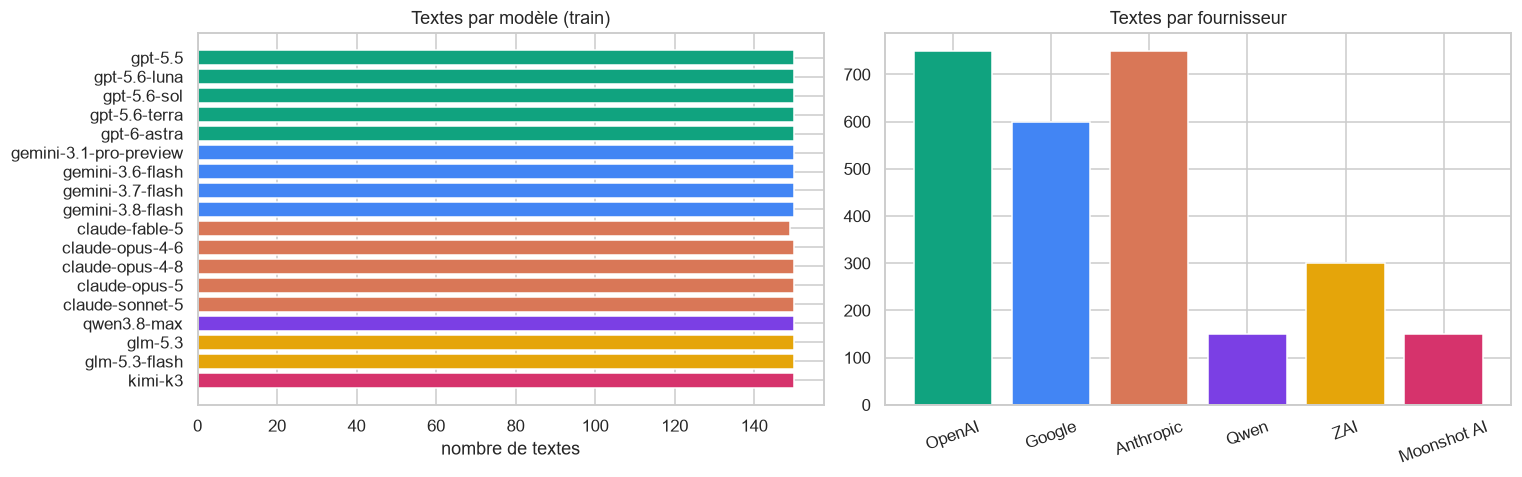

Le train est quasi parfaitement équilibré, mais le test ne l'est pas -> métrique = balanced accuracy.


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
counts = train['model'].value_counts().reindex(MODEL_ORDER)
axes[0].barh(counts.index, counts.values, color=[MODEL_COLORS[m] for m in counts.index])
axes[0].invert_yaxis(); axes[0].set_title('Textes par modèle (train)'); axes[0].set_xlabel('nombre de textes')

pc = train['provider'].value_counts().reindex(PROV_ORDER)
axes[1].bar(pc.index, pc.values, color=[PROV_COLORS[p] for p in pc.index])
axes[1].set_title('Textes par fournisseur'); axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

print('Le train est quasi parfaitement équilibré, mais le test ne l\'est pas -> métrique = balanced accuracy.')

## 2. Longueur des textes
Le sujet de la compétition précise que les longueurs varient aléatoirement entre 40 et 250 mots : la longueur ne doit pas être un raccourci.

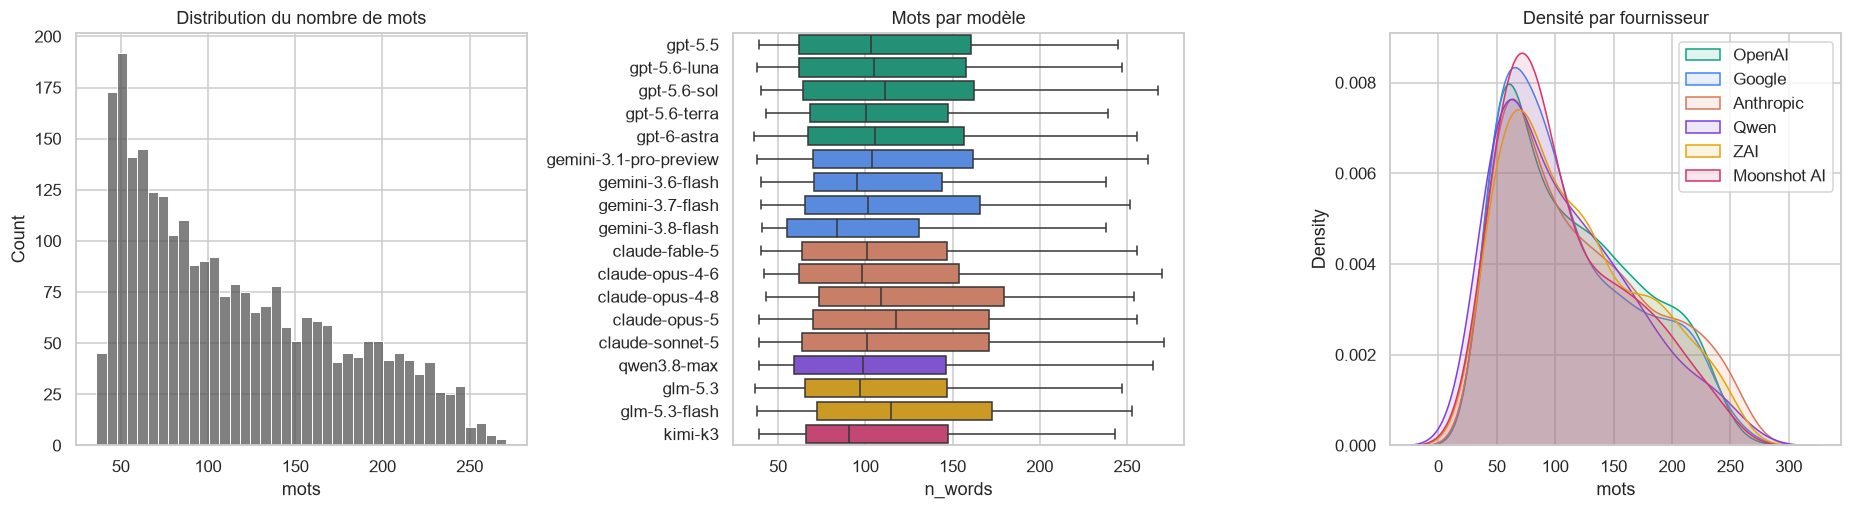

Variance de n_words expliquée par le modèle : 1.0%


In [3]:
WORD_RE = re.compile(r"[\w'’-]+")
train['n_words'] = train['text'].map(lambda t: len(WORD_RE.findall(t)))
train['n_chars'] = train['text'].str.len()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.histplot(train['n_words'], bins=40, ax=axes[0], color='#555')
axes[0].set_title('Distribution du nombre de mots'); axes[0].set_xlabel('mots')

sns.boxplot(data=train, y='model', x='n_words', order=MODEL_ORDER, palette=MODEL_COLORS, ax=axes[1], fliersize=2)
axes[1].set_title('Mots par modèle'); axes[1].set_ylabel('')

for p in PROV_ORDER:
    sns.kdeplot(train.loc[train['provider'] == p, 'n_words'], ax=axes[2], label=p, color=PROV_COLORS[p], fill=True, alpha=.12)
axes[2].set_title('Densité par fournisseur'); axes[2].legend(); axes[2].set_xlabel('mots')
plt.tight_layout(); plt.show()

# La longueur seule discrimine-t-elle ? (ANOVA : part de variance expliquée par le modèle)
def eta2(df, col, by='model'):
    g = df.groupby(by)[col]
    ss_between = (g.count() * (g.mean() - df[col].mean()) ** 2).sum()
    return ss_between / ((df[col] - df[col].mean()) ** 2).sum()

print(f"Variance de n_words expliquée par le modèle : {eta2(train, 'n_words'):.1%}")

## 3. Structure des prompts
Chaque prompt a été posé aux 18 modèles : on peut donc comparer des réponses **au même sujet**, ce qui isole le style.

In [4]:
per_prompt = train.groupby('prompt_id').size()
print(f'{train.prompt_id.nunique()} prompts | textes par prompt : min={per_prompt.min()} médiane={int(per_prompt.median())} max={per_prompt.max()}')

# Matrice prompt x modèle : chaque case = 1 texte (vérifie que le plan est bien "complet")
pm = (train.assign(v=1).pivot_table(index='prompt_id', columns='model', values='v', aggfunc='sum')
      .reindex(columns=MODEL_ORDER))
print('Cases vides (prompt, modèle) :', int(pm.isna().sum().sum()), '| cases > 1 :', int((pm > 1).sum().sum()))

# Une même question, 18 réponses (début de chaque texte)
pid = train['prompt_id'].iloc[0]
sub = train[train.prompt_id == pid].set_index('model').reindex(MODEL_ORDER).dropna(subset=['text'])
print(f'\n=== Prompt {pid} : premières phrases de chaque modèle ===')
for m, r in sub.iterrows():
    print(f"\n[{m}] ({int(r['n_words'])} mots)")
    print(textwrap.fill(r['text'][:350].replace('\n', ' ⏎ ') + '…', 110))

150 prompts | textes par prompt : min=17 médiane=18 max=18
Cases vides (prompt, modèle) : 1 | cases > 1 : 0

=== Prompt p081 : premières phrases de chaque modèle ===

[gpt-5.5] (227 mots)
When a language goes extinct, the loss is not only a silence among people but a dimming of the universe as it
was known through them. Gone are the names that divided darkness into kinds: the blue-black before rain, the
star-thick dark of winter, the moonless dark in which certain insects begin to sing. Gone are verbs that may
have treated mountains…

[gpt-5.6-luna] (159 mots)
When a language falls silent, the cosmos does not lose its stars, but it loses a way of arranging their
meaning. Gone may be the grammar that places the speaker inside a living web rather than outside an object,
the names that remember which winds arrive as ancestors, which constellations guide migrations, and which moon
belongs to planting, mourni…

[gpt-5.6-sol] (171 mots)
When a language goes extinct, the cosmos does not merel

## 4. Empreintes stylistiques
Pour chaque texte : fréquence (pour 100 mots) de signes de ponctuation, de balises markdown, de typographie, etc.
Ce sont des indices **indépendants du sujet**.

In [5]:
def style_features(t):
    words = WORD_RE.findall(t)
    nw = max(len(words), 1)
    sents = [s for s in re.split(r'(?<=[.!?])\s+', t.strip()) if s]
    per100 = lambda n: n / nw * 100
    return {
        # structure
        'avg_word_len': np.mean([len(w) for w in words]) if words else 0,
        'avg_sent_len': nw / max(len(sents), 1),
        'ttr (diversité lexicale)': len({w.lower() for w in words}) / nw,
        'paragraphes': len([p for p in re.split(r'\n\s*\n', t) if p.strip()]),
        'sauts_ligne/100m': per100(t.count('\n')),
        # ponctuation
        'virgules/100m': per100(t.count(',')),
        'point-virgules/100m': per100(t.count(';')),
        'deux-points/100m': per100(t.count(':')),
        'tirets cadratins —/100m': per100(t.count('—')),
        'tirets demi-cadratins –/100m': per100(t.count('–')),
        'traits d\'union/100m': per100(len(re.findall(r'\w-\w', t))),
        'parenthèses/100m': per100(t.count('(')),
        '! /100m': per100(t.count('!')),
        '? /100m': per100(t.count('?')),
        'ellipses/100m': per100(t.count('…') + t.count('...')),
        # typographie
        'guillemets courbes/100m': per100(len(re.findall('[“”‘’]', t))),
        'guillemets droits "/100m': per100(t.count('"')),
        'apostrophes droites/100m': per100(t.count("'")),
        'caractères non-ASCII/100m': per100(sum(ord(c) > 127 for c in t)),
        'chiffres/100m': per100(sum(c.isdigit() for c in t)),
        'ratio majuscules': sum(c.isupper() for c in t) / max(len(t), 1),
        # markdown
        'gras **/100m': per100(t.count('**')),
        'titres #': len(re.findall(r'(?m)^#+\s', t)),
        'puces': len(re.findall(r'(?m)^\s*[-*•]\s', t)),
        'LaTeX $ /100m': per100(t.count('$') + t.count('\\(')),
        # pronoms
        'je/I-me-my/100m': per100(len(re.findall(r"\b(?:I|me|my|I'm|I've)\b", t))),
        'nous/we-our/100m': per100(len(re.findall(r'\b(?:we|We|our|Our|us)\b', t))),
        'vous/you/100m': per100(len(re.findall(r'\b(?:you|You|your|Your)\b', t))),
    }

feats = pd.DataFrame([style_features(t) for t in train['text']])
F = pd.concat([train[['id', 'prompt_id', 'model', 'provider', 'n_words']], feats], axis=1)
FEAT_COLS = list(feats.columns)
print(len(FEAT_COLS), 'features de style calculées')

28 features de style calculées


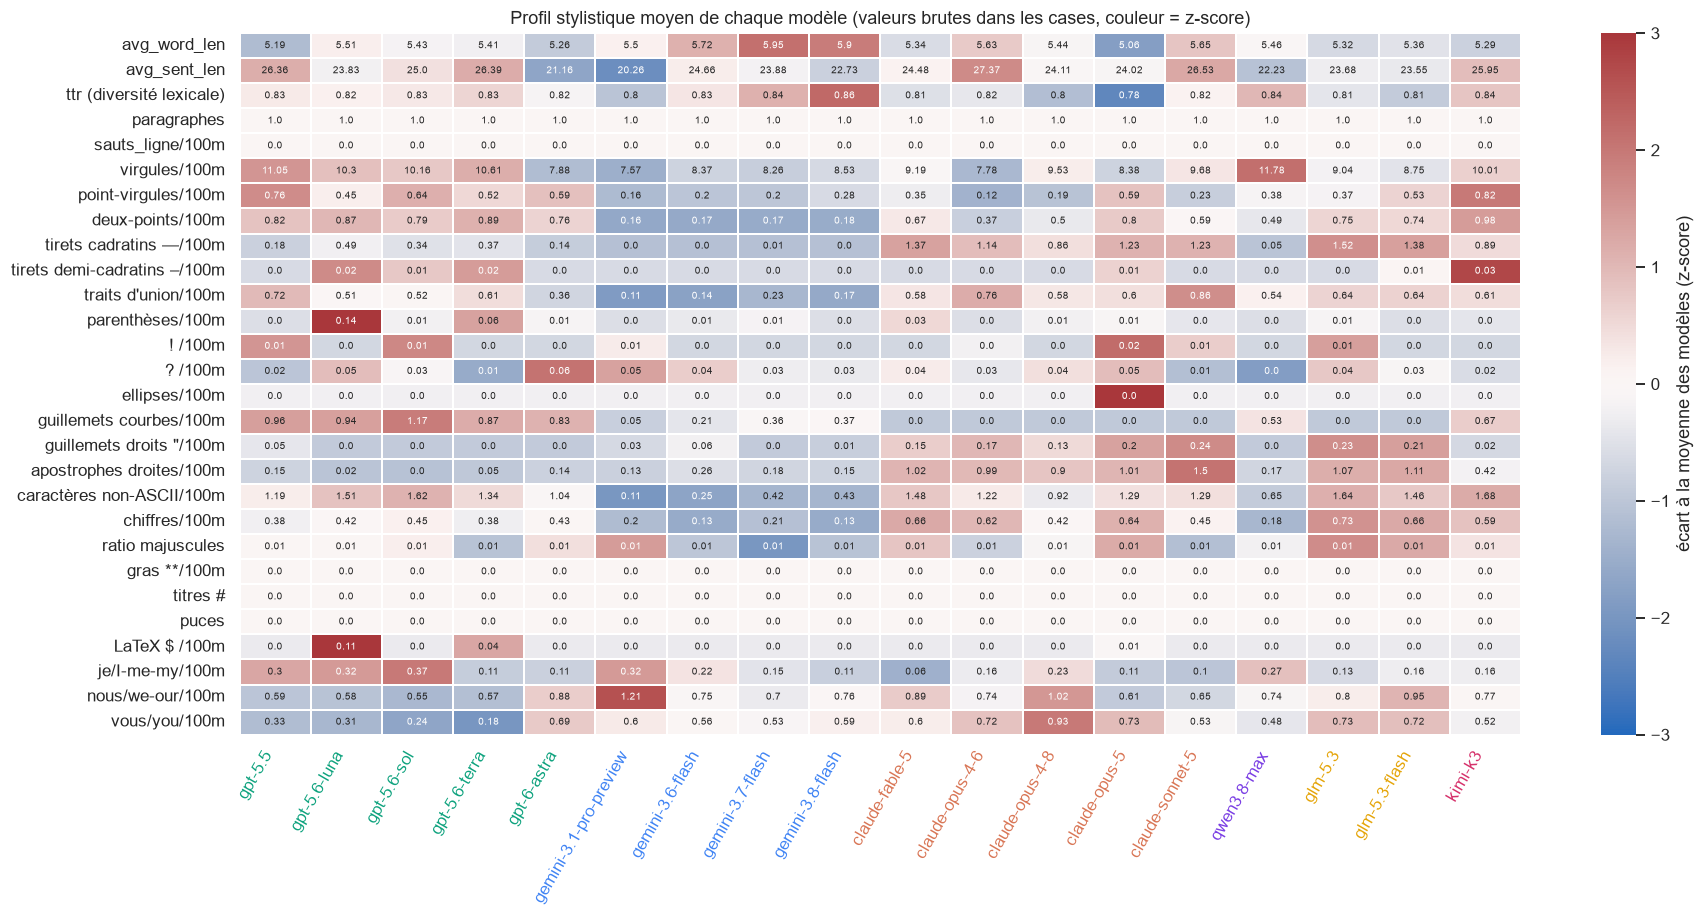

In [6]:
# Heatmap : moyenne par modèle, standardisée par colonne (z-score entre modèles)
M = F.groupby('model')[FEAT_COLS].mean().reindex(MODEL_ORDER)
Z = (M - M.mean()) / M.std(ddof=0).replace(0, 1)

fig, ax = plt.subplots(figsize=(17, 8.5))
sns.heatmap(Z.T, cmap='vlag', center=0, vmin=-3, vmax=3, annot=M.T.round(2), fmt='', annot_kws={'size': 6.5},
            cbar_kws={'label': 'écart à la moyenne des modèles (z-score)'}, linewidths=.3, ax=ax)
ax.set_title('Profil stylistique moyen de chaque modèle (valeurs brutes dans les cases, couleur = z-score)')
ax.set_xlabel(''); ax.set_ylabel('')
for lbl in ax.get_xticklabels(): lbl.set_color(MODEL_COLORS[lbl.get_text()])
plt.xticks(rotation=60, ha='right'); plt.tight_layout(); plt.show()

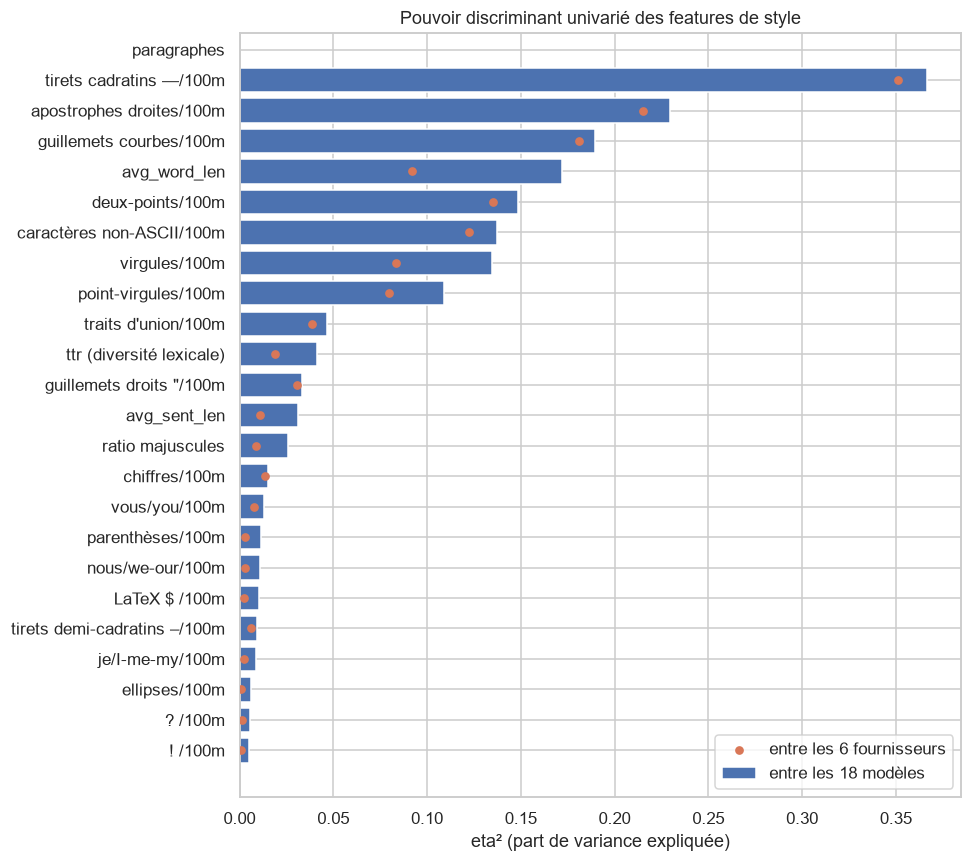

In [7]:
# Quelles features séparent le mieux les modèles ? (eta² : part de variance expliquée par le modèle)
imp = pd.Series({c: eta2(F, c) for c in FEAT_COLS}).sort_values()
imp_p = pd.Series({c: eta2(F, c, by='provider') for c in FEAT_COLS})

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(imp.index, imp.values, color='#4c72b0', label='entre les 18 modèles')
ax.scatter(imp_p.reindex(imp.index).values, imp.index, color='#d97757', zorder=3, s=22, label='entre les 6 fournisseurs')
ax.set_xlabel('eta² (part de variance expliquée)'); ax.set_title('Pouvoir discriminant univarié des features de style')
ax.legend(); plt.tight_layout(); plt.show()

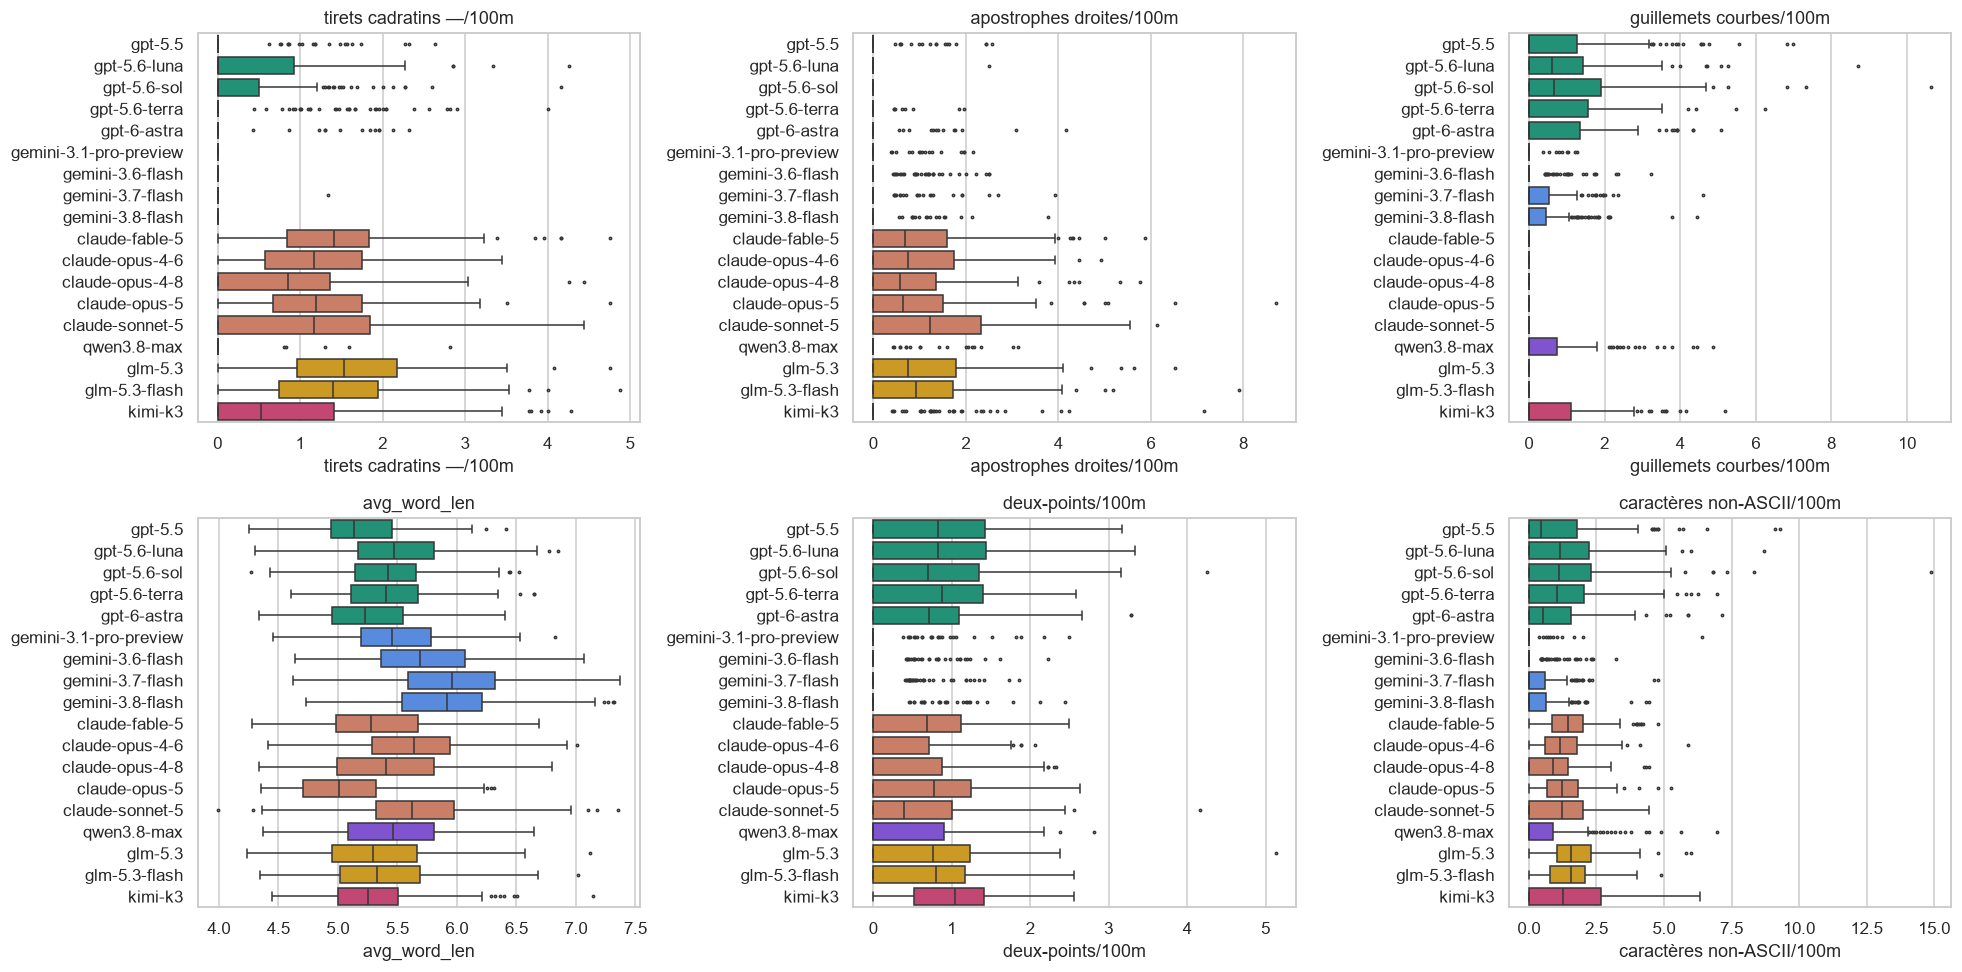

In [8]:
# Distribution des features les plus discriminantes, modèle par modèle
top = list(imp.sort_values(ascending=False).index[:6])
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, c in zip(axes.ravel(), top):
    sns.boxplot(data=F, y='model', x=c, order=MODEL_ORDER, palette=MODEL_COLORS, ax=ax, fliersize=1.5)
    ax.set_title(c); ax.set_ylabel('')
plt.tight_layout(); plt.show()

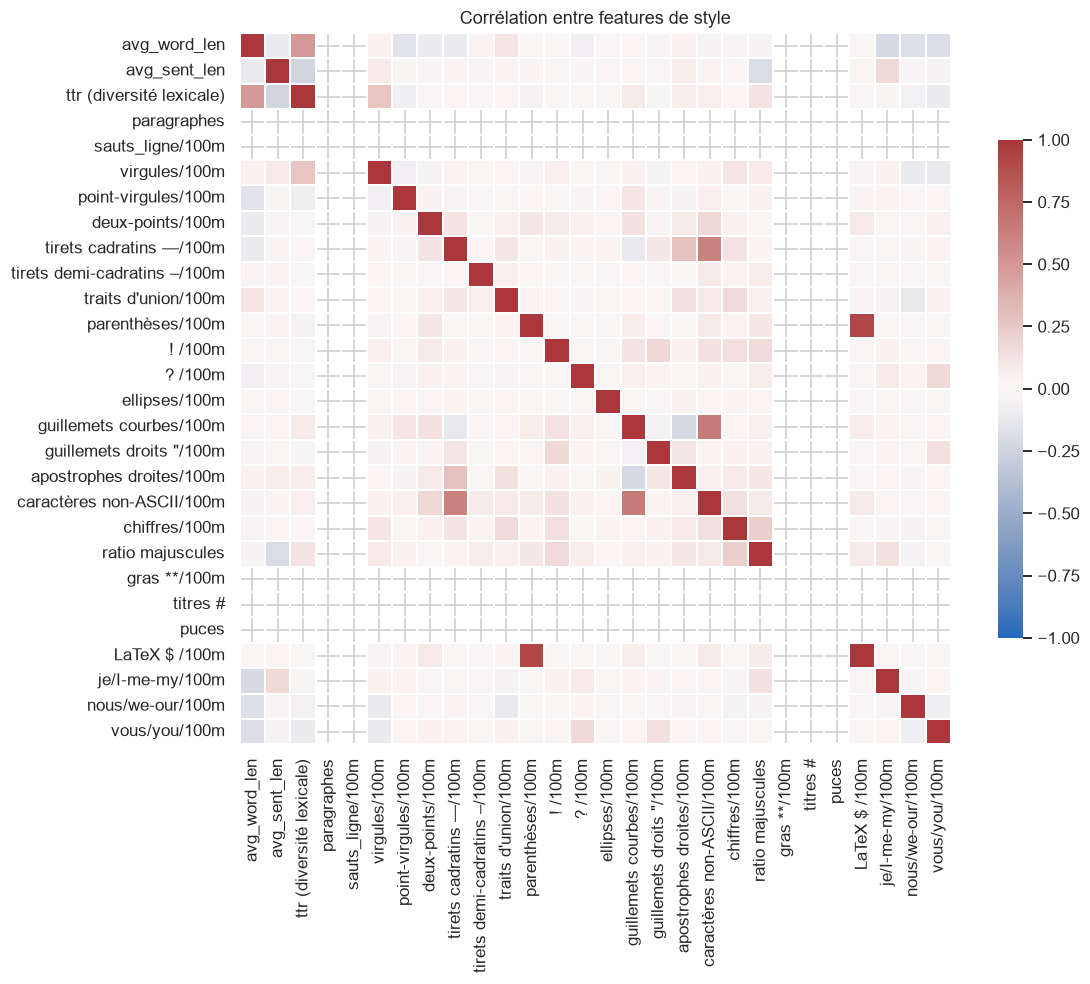

In [9]:
# Corrélation entre features (redondance) — utile pour choisir quoi garder dans un modèle tabulaire
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(F[FEAT_COLS].corr(), cmap='vlag', center=0, vmin=-1, vmax=1, square=True, linewidths=.2, ax=ax,
            cbar_kws={'shrink': .7})
ax.set_title('Corrélation entre features de style'); plt.tight_layout(); plt.show()

## 5. Vocabulaire et débuts de texte distinctifs

vocabulaire (1-2 grammes, df>=8) : 9033


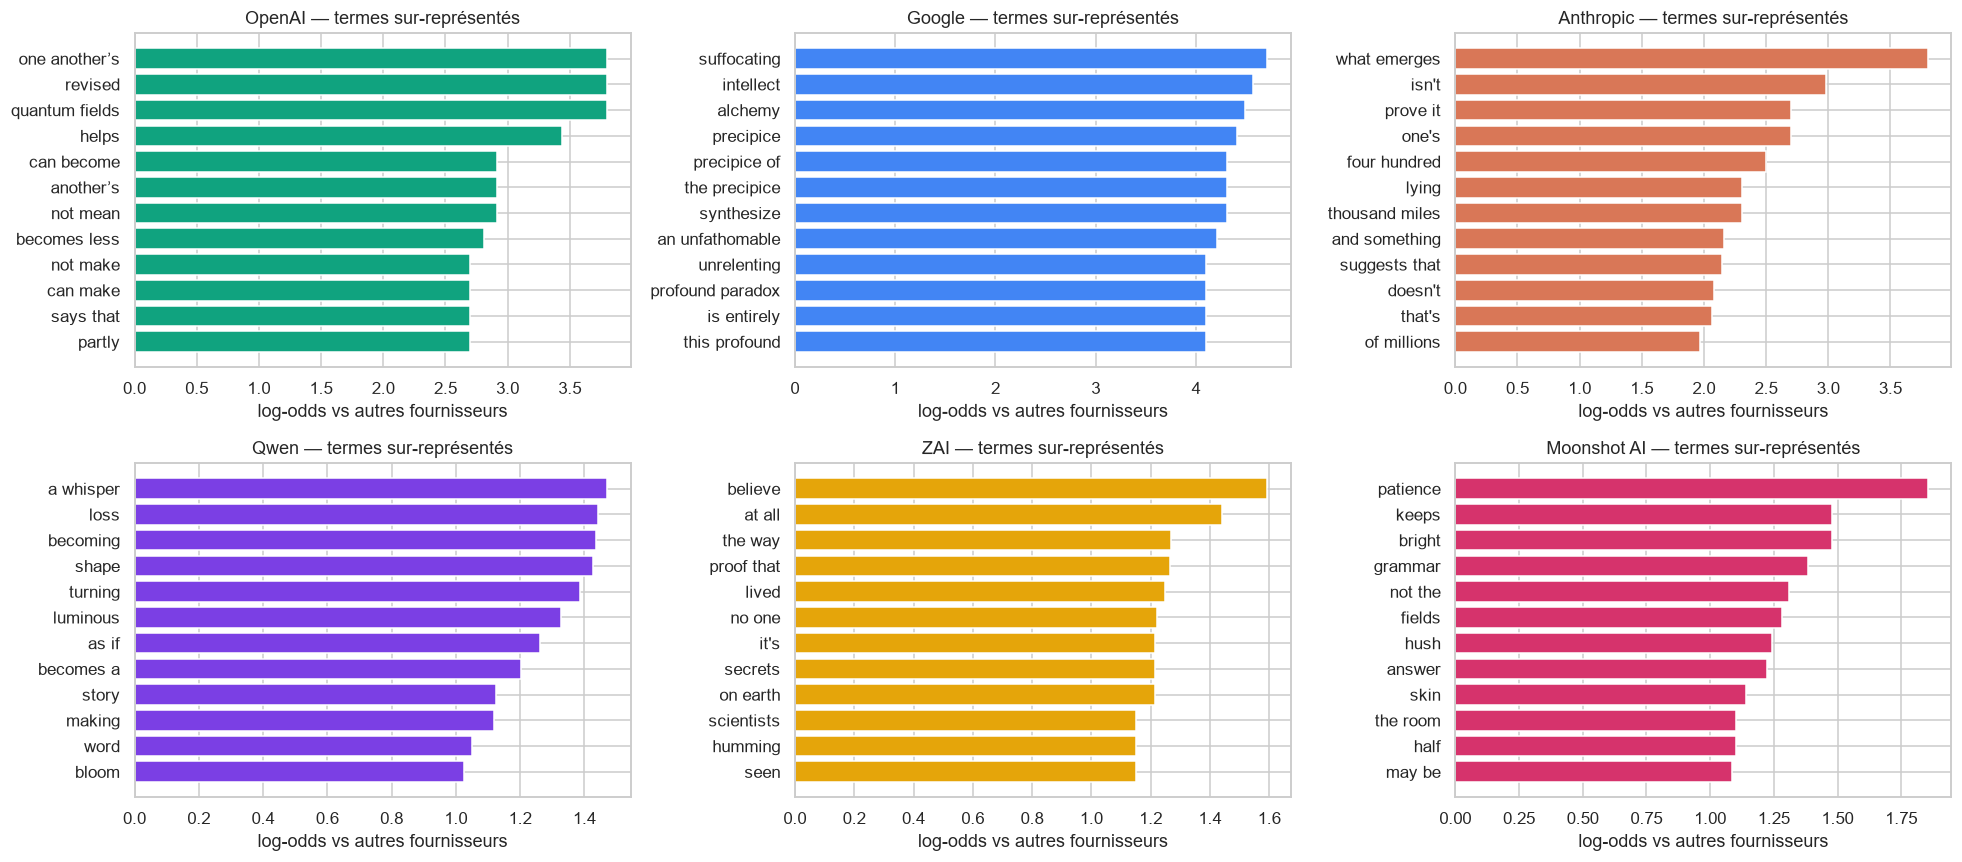

In [10]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(ngram_range=(1, 2), min_df=8, binary=True, lowercase=True, token_pattern=r"(?u)\b[\w'’]+\b")
X = cv.fit_transform(train['text'])
vocab = np.array(cv.get_feature_names_out())
print('vocabulaire (1-2 grammes, df>=8) :', len(vocab))

def distinctive_terms(mask, k=10, min_docs=8, a=0.5):
    # log-odds lissé sur la présence du terme dans un texte (classe vs reste)
    n1, n0 = mask.sum(), (~mask).sum()
    d1 = np.asarray(X[mask].sum(0)).ravel(); d0 = np.asarray(X[~mask].sum(0)).ravel()
    lo = np.log((d1 + a) / (n1 - d1 + a)) - np.log((d0 + a) / (n0 - d0 + a))
    lo[d1 < min_docs] = -np.inf
    idx = np.argsort(-lo)[:k]
    return list(zip(vocab[idx], lo[idx], d1[idx]))

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, p in zip(axes.ravel(), PROV_ORDER):
    t = distinctive_terms((train['provider'] == p).values, k=12)
    ax.barh([w for w, _, _ in t][::-1], [s for _, s, _ in t][::-1], color=PROV_COLORS[p])
    ax.set_title(f'{p} — termes sur-représentés')
    ax.set_xlabel('log-odds vs autres fournisseurs')
plt.tight_layout(); plt.show()

In [11]:
# Termes distinctifs par modèle (top 8)
rows = {m: ', '.join(w for w, _, _ in distinctive_terms((train['model'] == m).values, k=8)) for m in MODEL_ORDER}
pd.set_option('display.max_colwidth', 200)
pd.DataFrame({'termes distinctifs': rows})

,termes distinctifs
gpt-5.5,"maps, hunger, as if, seems to, constellations, attention, seems, heat"
gpt-5.6-luna,"records, gathers, gather, repeated, changing, less a, sometimes, seems to"
gpt-5.6-sol,"travel, change, beside, opens, seem, need, vanished, did not"
gpt-5.6-terra,"institutions, crowded, beneath a, changing, useful, distances, allowing, appear"
gpt-6-astra,"helps, shelter, is therefore, help, not that, leave, familiar, but that"
gemini-3.1-pro-preview,"acts as, the ultimate, a sudden, a profound, sprawling, a fleeting, ultimate, profound"
gemini-3.6-flash,"expanse of, dynamic, breathtaking, expanse, vibrant, terrifying, abstract, lies a"
gemini-3.7-flash,"an intricate, known as, fundamentally, consequently, perpetually, perpetual, subterranean, expanse"
gemini-3.8-flash,"enduring, subterranean, tapestry, fury, into an, as an, thermal, ancestral"
claude-fable-5,"at all, stranger, complete, everything, nearly, dissolves, nothing, atmosphere"


In [12]:
# Les 2 premiers mots d'un texte : très révélateurs du post-training
train['opener'] = train['text'].str.strip().str.split().str[:2].str.join(' ').str.lower()
top_open = (train.groupby('model')['opener']
            .agg(lambda s: ' | '.join(f'{k} ({v/len(s):.0%})' for k, v in s.value_counts().head(3).items()))
            .reindex(MODEL_ORDER))
pd.DataFrame({'ouvertures les plus fréquentes': top_open})

,ouvertures les plus fréquentes
model,
gpt-5.5,across the (3%) | at the (2%) | in a (2%)
gpt-5.6-luna,at the (3%) | in the (3%) | imagine a (3%)
gpt-5.6-sol,in the (3%) | at the (3%) | when a (2%)
gpt-5.6-terra,at the (4%) | across the (3%) | when the (3%)
gpt-6-astra,across the (3%) | in the (3%) | imagine a (3%)
gemini-3.1-pro-preview,in the (5%) | imagine a (3%) | deep within (3%)
gemini-3.6-flash,in the (5%) | beneath the (5%) | deep within (4%)
gemini-3.7-flash,beneath the (6%) | deep within (5%) | at the (4%)
gemini-3.8-flash,beneath the (5%) | across the (4%) | in the (4%)


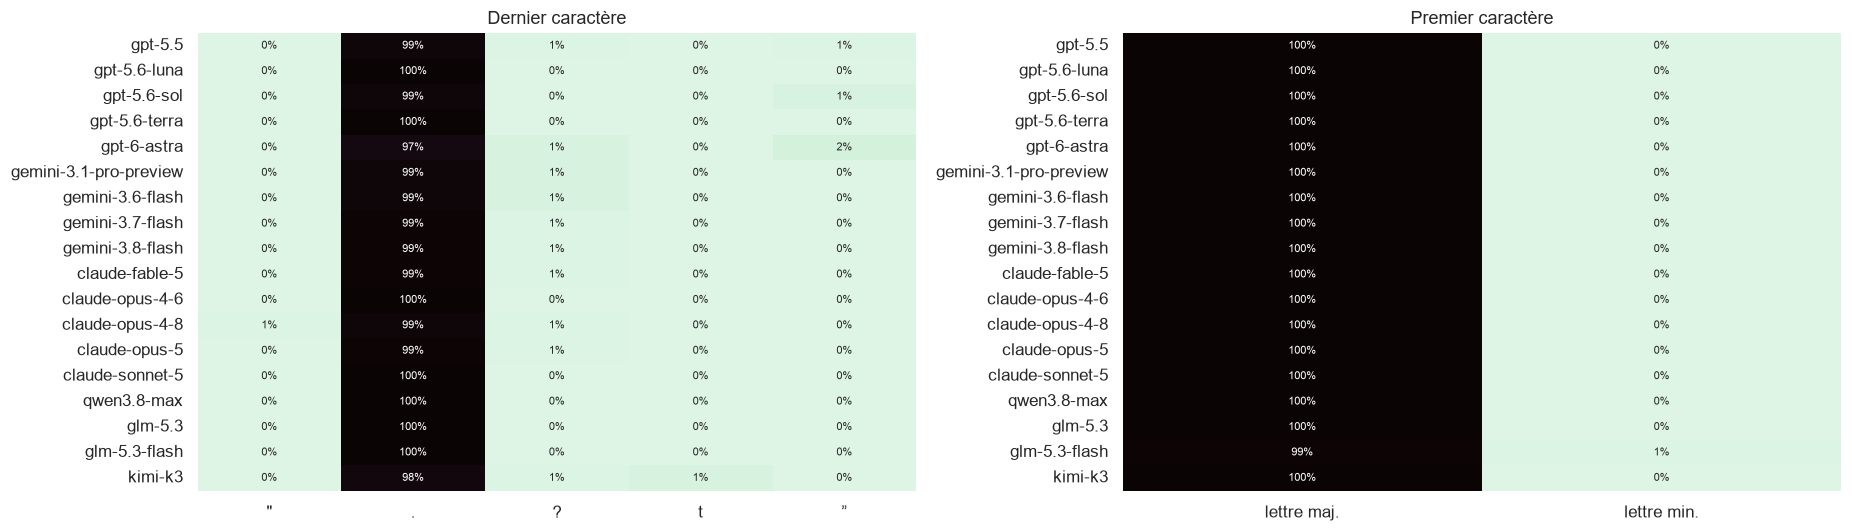

In [13]:
# Caractère de fin de texte & premier caractère (guillemet, tiret, markdown...)
train['last_char'] = train['text'].str.strip().str[-1]
train['first_char_type'] = train['text'].str.strip().str[0].map(
    lambda c: 'lettre maj.' if c.isupper() else 'lettre min.' if c.isalpha() else 'chiffre' if c.isdigit() else c)
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax, col, title in zip(axes, ['last_char', 'first_char_type'], ['Dernier caractère', 'Premier caractère']):
    keep = train[col].value_counts().head(8).index
    ct = pd.crosstab(train['model'], train[col].where(train[col].isin(keep), 'autre'), normalize='index').reindex(MODEL_ORDER)
    sns.heatmap(ct, cmap='mako_r', annot=True, fmt='.0%', annot_kws={'size': 7}, ax=ax, cbar=False)
    ax.set_title(title); ax.set_ylabel(''); ax.set_xlabel('')
plt.tight_layout(); plt.show()

## 6. Cartographie 2D : le sujet écrase-t-il le style ?
On projette les textes (TF-IDF → SVD → t-SNE) et on colore **par fournisseur** puis **par prompt**.
Si les couleurs « prompt » forment des îlots nets et pas les couleurs « fournisseur », le sujet domine le signal brut — d'où l'intérêt de la CV groupée par `prompt_id`.

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

def embed_2d(X_sparse, n_svd=50, seed=0):
    Z50 = TruncatedSVD(n_svd, random_state=seed).fit_transform(X_sparse)
    return TSNE(2, perplexity=30, init='pca', random_state=seed).fit_transform(Z50)

Xw = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True).fit_transform(train['text'])          # contenu (mots)
Xc = TfidfVectorizer(analyzer='char', ngram_range=(2, 4), min_df=5, sublinear_tf=True, max_features=60000).fit_transform(train['text'])  # style (caractères)
E_word, E_char = embed_2d(Xw), embed_2d(Xc)
E_style = TSNE(2, perplexity=30, init='pca', random_state=0).fit_transform(StandardScaler().fit_transform(F[FEAT_COLS]))
print('ok')

ok


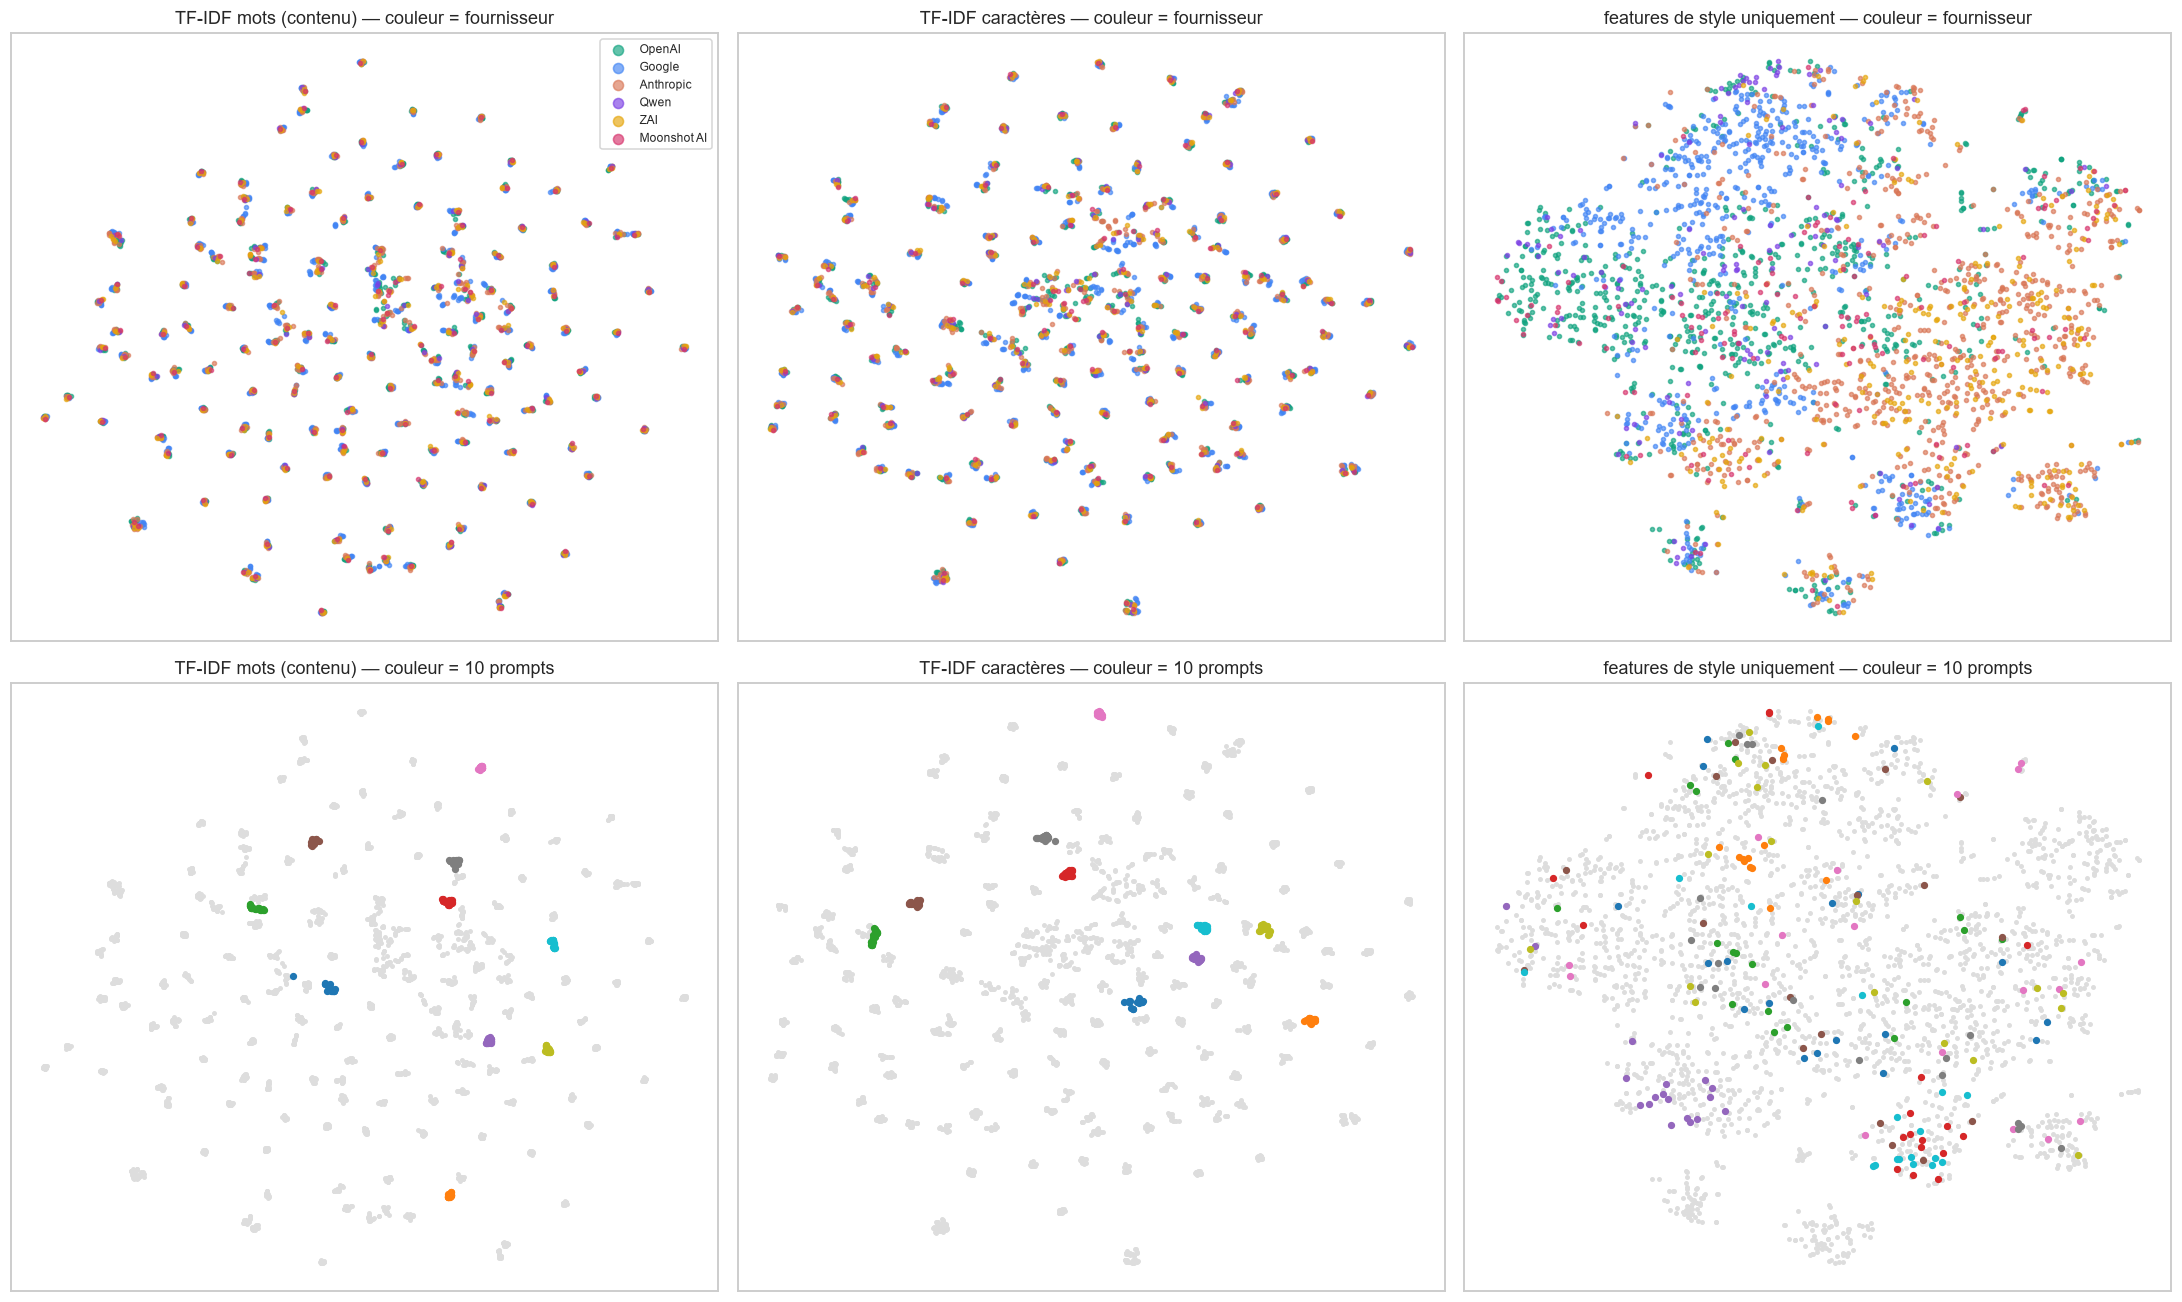

In [15]:
top_prompts = train['prompt_id'].value_counts().index[:10]
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for j, (E, name) in enumerate([(E_word, 'TF-IDF mots (contenu)'), (E_char, 'TF-IDF caractères'), (E_style, 'features de style uniquement')]):
    for p in PROV_ORDER:
        m = (train['provider'] == p).values
        axes[0, j].scatter(E[m, 0], E[m, 1], s=7, alpha=.65, color=PROV_COLORS[p], label=p)
    axes[0, j].set_title(f'{name} — couleur = fournisseur'); axes[0, j].set_xticks([]); axes[0, j].set_yticks([])
    axes[1, j].scatter(E[:, 0], E[:, 1], s=5, color='#ddd')
    cmap = plt.get_cmap('tab10')
    for i, pid in enumerate(top_prompts):
        m = (train['prompt_id'] == pid).values
        axes[1, j].scatter(E[m, 0], E[m, 1], s=14, color=cmap(i))
    axes[1, j].set_title(f'{name} — couleur = 10 prompts'); axes[1, j].set_xticks([]); axes[1, j].set_yticks([])
axes[0, 0].legend(markerscale=2.5, fontsize=8)
plt.tight_layout(); plt.show()

## 7. Sujet ou style ? Mesure par similarité
Similarité cosinus moyenne entre paires de textes, selon qu'ils partagent le prompt, le modèle, ou le fournisseur.

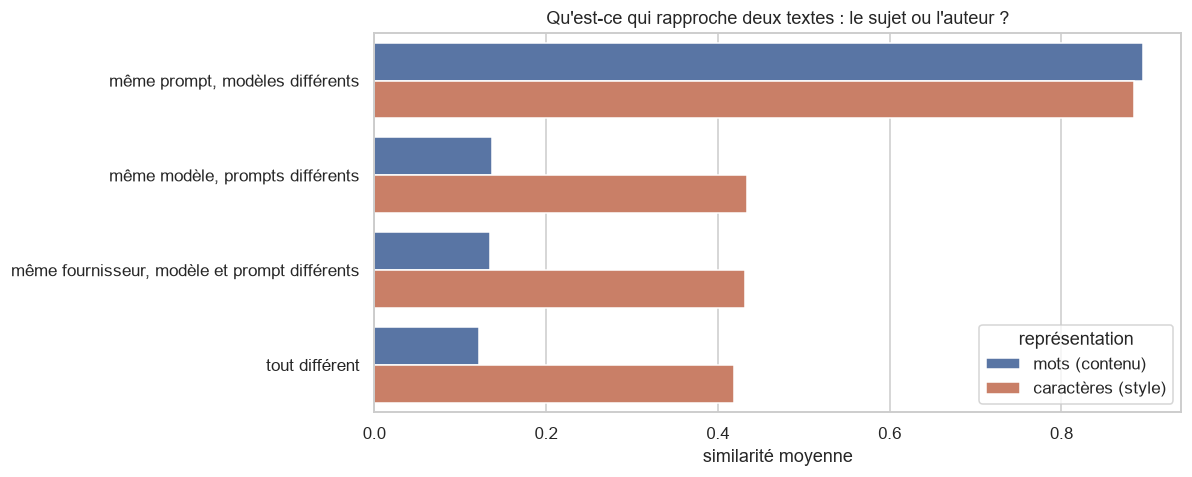

représentation,caractères (style),mots (contenu)
paires,,
"même fournisseur, modèle et prompt différents",0.4313,0.1349
"même modèle, prompts différents",0.4343,0.1373
"même prompt, modèles différents",0.8839,0.8949
tout différent,0.4192,0.1223


In [16]:
from sklearn.preprocessing import normalize

rng = np.random.default_rng(0)
n = len(train)
I = rng.integers(0, n, 300000); J = rng.integers(0, n, 300000)
keep = I != J; I, J = I[keep], J[keep]

pr, mo, pv = train['prompt_id'].values, train['model'].values, train['provider'].values
def pair_sims(X):
    # SVD 100 dims puis cosinus sur vecteurs denses (évite de matérialiser 300k paires creuses)
    Zd = normalize(TruncatedSVD(100, random_state=0).fit_transform(X))
    return (Zd[I] * Zd[J]).sum(1)

groups = {
    'même prompt, modèles différents': (pr[I] == pr[J]) & (mo[I] != mo[J]),
    'même modèle, prompts différents': (pr[I] != pr[J]) & (mo[I] == mo[J]),
    'même fournisseur, modèle et prompt différents': (pr[I] != pr[J]) & (mo[I] != mo[J]) & (pv[I] == pv[J]),
    'tout différent': (pr[I] != pr[J]) & (pv[I] != pv[J]),
}
res = []
for name, X_ in [('mots (contenu)', Xw), ('caractères (style)', Xc)]:
    s = pair_sims(X_)
    for g, m in groups.items():
        res.append({'représentation': name, 'paires': g, 'similarité moyenne': s[m].mean()})
res = pd.DataFrame(res)
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=res, y='paires', x='similarité moyenne', hue='représentation', ax=ax, palette=['#4c72b0', '#d97757'])
ax.set_ylabel(''); ax.set_title('Qu\'est-ce qui rapproche deux textes : le sujet ou l\'auteur ?')
plt.tight_layout(); plt.show()
res.pivot(index='paires', columns='représentation', values='similarité moyenne').round(4)

## 8. Baseline rapide & matrice de confusion
TF-IDF (mots + caractères) + régression logistique, validation **GroupKFold par `prompt_id`** (comme le test : prompts inconnus), métrique = balanced accuracy.

In [17]:
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, recall_score

pipe = Pipeline([
    ('f', FeatureUnion([
        ('w', TfidfVectorizer(ngram_range=(1, 2), max_features=25000, sublinear_tf=True)),
        ('c', TfidfVectorizer(analyzer='char', ngram_range=(3, 5), max_features=35000, sublinear_tf=True)),
    ])),
    ('clf', LogisticRegression(C=2.0, max_iter=400, class_weight='balanced')),
])
oof = cross_val_predict(pipe, train['text'], train['model'], groups=train['prompt_id'],
                        cv=GroupKFold(5), n_jobs=-1)
bacc = balanced_accuracy_score(train['model'], oof)
print(f'Balanced accuracy (CV groupée) : {bacc:.4f}   | hasard = {1/18:.4f}')

Balanced accuracy (CV groupée) : 0.3152   | hasard = 0.0556


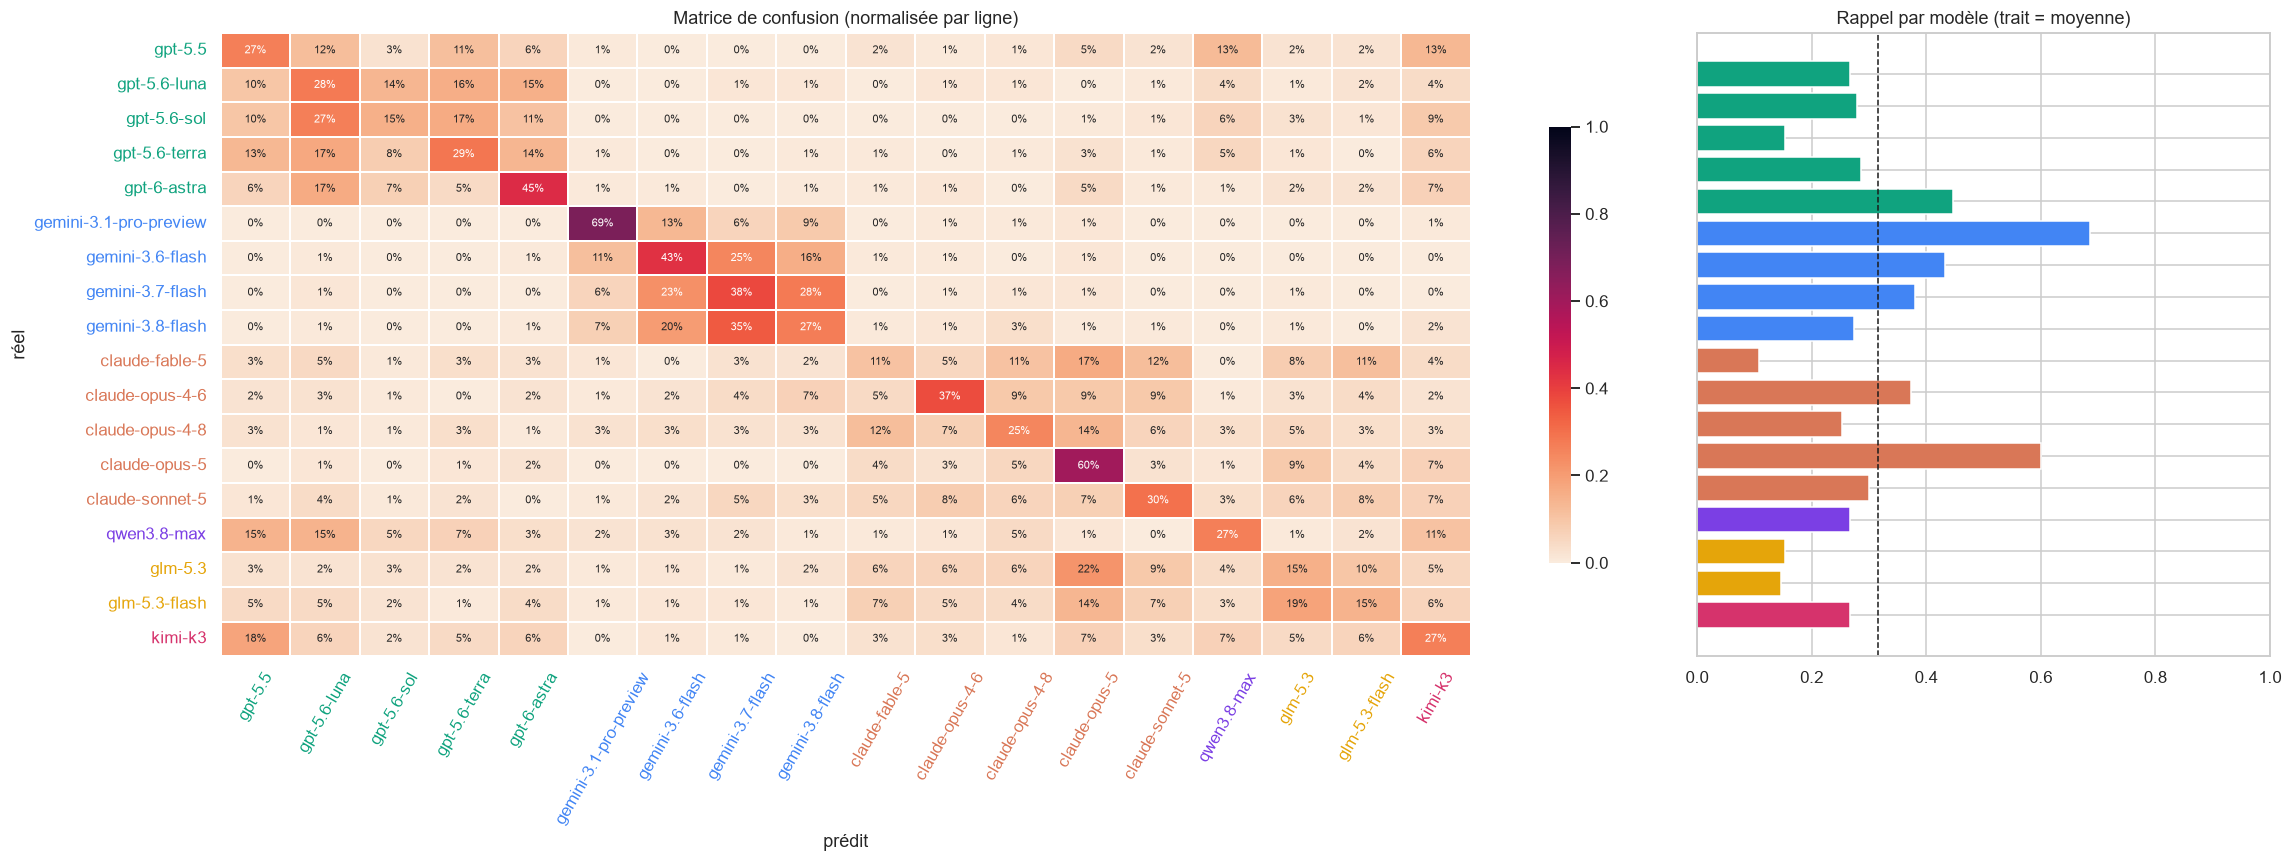

In [18]:
cm = confusion_matrix(train['model'], oof, labels=MODEL_ORDER, normalize='true')
fig, axes = plt.subplots(1, 2, figsize=(21, 8), gridspec_kw={'width_ratios': [3, 1.1]})
sns.heatmap(cm, cmap='rocket_r', vmin=0, vmax=1, annot=True, fmt='.0%', annot_kws={'size': 7},
            xticklabels=MODEL_ORDER, yticklabels=MODEL_ORDER, linewidths=.3, ax=axes[0], cbar_kws={'shrink': .7})
axes[0].set_xlabel('prédit'); axes[0].set_ylabel('réel'); axes[0].set_title('Matrice de confusion (normalisée par ligne)')
for lbl in axes[0].get_xticklabels() + axes[0].get_yticklabels(): lbl.set_color(MODEL_COLORS[lbl.get_text()])
axes[0].tick_params(axis='x', rotation=60)

rec = pd.Series(recall_score(train['model'], oof, labels=MODEL_ORDER, average=None), index=MODEL_ORDER)
axes[1].barh(rec.index, rec.values, color=[MODEL_COLORS[m] for m in rec.index])
axes[1].invert_yaxis(); axes[1].set_xlim(0, 1); axes[1].axvline(bacc, ls='--', color='k', lw=1)
axes[1].set_title('Rappel par modèle (trait = moyenne)'); axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()

In [19]:
# Confusions au niveau fournisseur vs. au sein d'un même fournisseur
pred_prov = pd.Series(oof).map(PROVIDER)
same_prov = (pred_prov.values == train['provider'].values)
correct = (oof == train['model'].values)
print(f'Fournisseur correct : {same_prov.mean():.1%}  | modèle correct : {correct.mean():.1%}')
print(f'Parmi les erreurs de modèle, {(same_prov & ~correct).sum() / (~correct).sum():.1%} restent dans la bonne famille.')

pairs = (pd.DataFrame({'réel': train['model'], 'prédit': oof}).query('réel != prédit')
         .value_counts().head(12).rename('erreurs').reset_index())
pairs

Fournisseur correct : 66.2%  | modèle correct : 31.5%
Parmi les erreurs de modèle, 50.7% restent dans la bonne famille.


,réel,prédit,erreurs
0,gemini-3.8-flash,gemini-3.7-flash,52
1,gemini-3.7-flash,gemini-3.8-flash,42
2,gpt-5.6-sol,gpt-5.6-luna,40
3,gemini-3.6-flash,gemini-3.7-flash,38
4,gemini-3.7-flash,gemini-3.6-flash,34
5,glm-5.3,claude-opus-5,33
6,gemini-3.8-flash,gemini-3.6-flash,30
7,glm-5.3-flash,glm-5.3,28
8,kimi-k3,gpt-5.5,27
9,gpt-5.6-terra,gpt-5.6-luna,26


## 9. Train vs test

In [ ]:
test['n_words'] = test['text'].map(lambda t: len(WORD_RE.findall(t)))
print(f'test local : {len(test)} lignes (le vrai test, ~4000 textes, n\'est accessible qu\'à la soumission)')
if len(test) >= 30:
    sns.kdeplot(train['n_words'], label='train', fill=True, alpha=.2); sns.kdeplot(test['n_words'], label='test', fill=True, alpha=.2)
    plt.legend(); plt.title('Longueur : train vs test'); plt.show()
else:
    display(test.assign(extrait=test['text'].str[:160])[['id', 'n_words', 'extrait']])

test local : 3 lignes (le vrai test, ~4000 textes, n'est accessible qu'à la soumission)


,id,n_words,extrait
0,00353fb1c541,48,"The more efficiently we use a resource, the more of it we ultimately consume: cheaper energy from efficiency gains invites expanded use, eroding the very saving"
1,005f5a9a6139,111,"The Stern-Gerlach experiment, performed in 1922 by Otto Stern and Walther Gerlach, sent a narrow beam of neutral silver atoms through a strongly nonuniform magn"
2,0062a53d5487,149,"Hundreds of millions of years ago, fluctuating climates and tectonic shifts isolated massive landlocked seas, exposing them to relentless solar baking. As the b"


: 

## 10. Conclusions de l'exploration

- **Équilibre** : le train compte ≈150 textes par modèle (149 pour `claude-fable-5`), sur 150 prompts × 18 modèles (une seule case prompt/modèle vide). Le test est déséquilibré : pondérer les classes et optimiser la *balanced accuracy*.
- **Longueur** : le modèle n'explique que ~1 % de la variance du nombre de mots. Ce n'est pas un raccourci exploitable.
- **Le sujet domine le texte brut** : deux textes du même prompt se ressemblent à ~0,89 (TF-IDF mots), contre ~0,13 pour deux textes de même modèle sur des prompts différents (≈ le niveau de deux textes sans lien, 0,12). Toute validation doit donc être **groupée par `prompt_id`**.
- **Le style existe mais est subtil** : les features les plus discriminantes sont les tirets cadratins `—` (η² ≈ 0,37), les apostrophes droites (0,23), les guillemets courbes (0,19), la longueur moyenne des mots (0,17) et les deux-points (0,15). Les termes distinctifs montrent aussi des signatures de famille : Gemini (« expanse », « tapestry », « beneath the », « deep within »), GPT (« seems to », « as if »), Claude (« the very », « it's »).
- **Baseline TF-IDF + régression logistique** (CV groupée) : balanced accuracy ≈ **0,315** (hasard : 0,056).
  - Le fournisseur est correct dans 66 % des cas, le modèle dans 31,5 %.
  - La moitié des erreurs restent dans la bonne famille : les confusions principales sont `gemini-3.8-flash` ↔ `gemini-3.7-flash` ↔ `gemini-3.6-flash`, `gpt-5.6-sol`/`terra`/`astra` → `gpt-5.6-luna`, `glm-5.3` ↔ `glm-5.3-flash`.
  - Aussi des confusions entre fournisseurs : `glm-5.3` → `claude-opus-5`, `kimi-k3` → `gpt-5.5`.
- **Pistes suivantes** :
  1. ajouter les features de style (tirets, guillemets, apostrophes, ponctuation) à un modèle tabulaire (LightGBM) empilé avec TF-IDF ;
  2. tester des n-grammes de caractères plus longs et des mots-outils uniquement, pour réduire l'influence du sujet ;
  3. fine-tuner un encodeur (DeBERTa / ModernBERT) ;
  4. ajouter un classifieur de second étage pour départager les modèles d'une même famille ;
  5. régler les seuils par classe pour la balanced accuracy.